# Aim of the notebook
We extract all per-gene characteristics of the datasets
# Load modules

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns

parent_dir = os.path.abspath(os.path.join(os.getcwd(), "../../src/troutpy_reproducibility"))
# Add parent directory to sys.path
sys.path.append(parent_dir)

from batch_running import *

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [2]:
import os
import spatialdata as sd
import pandas as pd

main_path = '/media/sergio/Meninges/troutpy/rois/'
saving_path='/media/sergio/Meninges/troutpy/figures'

combined_df = []

# Get list of subdirectories
for subdir in os.listdir(main_path):
    sub_path = os.path.join(main_path, subdir)
    zarr_path = os.path.join(sub_path, 'data_processed.zarr')
    print(sub_path)

    if os.path.isdir(sub_path) and os.path.exists(zarr_path):
        try:
            sdata = sd.read_zarr(zarr_path)
            df = sdata['xrna_metadata'].var.copy()
            df['dataset'] = subdir
            combined_df.append(df)
        except Exception as e:
            print(f"Failed to read {zarr_path}: {e}")

# Combine all dataframes
if combined_df:
    all_data = pd.concat(combined_df, axis=0)
    print("Combined table shape:", all_data.shape)
else:
    all_data = pd.DataFrame()
    print("No data was loaded.")

# Optional: Save to file
# all_data.to_csv("combined_xrna_metadata.csv")


/media/sergio/Meninges/troutpy/rois/cosmx_hgsoc
/media/sergio/Meninges/troutpy/rois/cosmx_melanoma
/media/sergio/Meninges/troutpy/rois/cosmx_mousebrain
/media/sergio/Meninges/troutpy/rois/cosmx_pancreas
Failed to read /media/sergio/Meninges/troutpy/rois/cosmx_pancreas/data_processed.zarr: 
/media/sergio/Meninges/troutpy/rois/cosmx_stomach
/media/sergio/Meninges/troutpy/rois/merscope_hsbrain
/media/sergio/Meninges/troutpy/rois/merscope_hsuterine
/media/sergio/Meninges/troutpy/rois/xenium_hsfemur
/media/sergio/Meninges/troutpy/rois/xenium_hsheart
/media/sergio/Meninges/troutpy/rois/xenium_hsprostate
/media/sergio/Meninges/troutpy/rois/xenium_hsputamen
/media/sergio/Meninges/troutpy/rois/xenium_hsskin_5k
/media/sergio/Meninges/troutpy/rois/xenium_msbrain_300
/media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k
/media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k_large
/media/sergio/Meninges/troutpy/rois/xenium_mscolon_5k
Combined table shape: (35020, 15)


In [4]:
all_data['Gene']=all_data.index
all_data=all_data.reset_index()

# Reading metadata

In [5]:
import os
import pandas as pd

# Define the root directory
root_dir = "/media/sergio/Meninges/troutpy/rois"
saving_path='/media/sergio/Meninges/troutpy/figures'


# Initialize an empty list to hold individual metadata DataFrames
metadata_list = []

# List only first-level subdirectories
subfolders = [f.path for f in os.scandir(root_dir) if f.is_dir()]

for subfolder in subfolders:
    metadata_path = os.path.join(subfolder, "metadata.csv")
    if os.path.isfile(metadata_path):
        try:
            df = pd.read_csv(metadata_path)
            df['tag']=subfolder.split('/')[-1]
            # Add subfolder name as a column
            metadata_list.append(df)
        except Exception as e:
            print(f"Failed to read {metadata_path}: {e}")

# Combine all metadata files into a single DataFrame
if metadata_list:
    combined_metadata = pd.concat(metadata_list, ignore_index=True)
    print("Combined metadata shape:", combined_metadata.shape)
else:
    print("No metadata.csv files found.")

Combined metadata shape: (15, 15)


In [8]:
all_control=all_data[all_data['control_probe']==True]

In [48]:
combined_metadata

,sample_id,species,technology,segmentation_method,roi_name,tissue,disease,total_cells,total_cellular_transcripts,proportion_cellular_transcripts,total_transcripts,total_genes,area_profiled_um2,cell_density_per_mm2,tag
0,human_hgsoc,Hommo Sapiens,CosMx,cosmx-default,roi_hs_hgsoc,Ovary,serous ovarian carcinoma,1653,184297,0.733617,251217,979,6.291790e+06,262.723325,cosmx_hgsoc
1,human_melanoma,Hommo Sapiens,CosMx,cosmx-default,roi_hs_melanoma,skin,melanoma,4754,2915880,0.957969,3043815,987,6.329515e+06,751.084361,cosmx_melanoma
2,cosmx_mshippocampus,Mus musculus,CosMx,cosmx-default,roi_ms_cortex_ad,Brain (hippocampus),Alzheimer's disease model,11291,11921036,0.626972,19013669,960,1.625904e+08,69.444453,cosmx_mousebrain
3,human_pancreas,Homo Sapiens,CosMx,cosmx-default,roi_hs_pancreas,pancreas,NaN,2429,3213320,0.951056,3378688,21731,3.842686e+08,6.321099,cosmx_pancreas
4,human_stomach,Hommo Sapiens,CosMx,cosmx-default,roi_hs_stomach,stomach,NaN,6826,746527,0.874159,853995,979,6.346376e+06,1075.574433,cosmx_stomach
5,merscope_human_brain,Homo Sapiens,MERSCOPE,MERSCOPE,brain_ROI,brain,alzheimer,1707,248383,0.814237,305050,960,2.112012e+07,80.823413,merscope_hsbrain
6,merscope_human_uterine,Homo Sapiens,MERSCOPE,MERSCOPE,uterine_cancer_ROI,uterus,cancer,11432,5301580,0.796418,6656782,500,2.644695e+07,432.261497,merscope_hsuterine
7,human_bone,Homo Sapiens,Xenium,nuclei_expanded,human_bone,bone,control,33801,685345,0.508524,1347715,477,1.981349e+09,17.059589,xenium_hsfemur
8,human_heart,Homo Sapiens,Xenium,nuclei_expanded,human_heart,heart,control,26366,1822577,0.743464,2451466,377,4.307469e+08,61.209952,xenium_hsheart
9,human_prostate_5k,Homo Sapiens,Xenium,multimodal,prostate,prostate,prostate cancer,7024,1362305,0.623493,2184955,5006,4.085399e+07,171.929355,xenium_hsprostate


In [49]:
tag2area=dict(zip(combined_metadata['tag'],combined_metadata['area_profiled_um2']))
tag2tech=dict(zip(combined_metadata['tag'],combined_metadata['technology']))
all_control['area_profiled_um2']=all_control['dataset'].map(tag2area)
all_control['technology']=all_control['dataset'].map(tag2tech)

In [76]:
all_control['control_density']=(all_control['count']/all_control['area_profiled_um2'])*1e6

In [77]:
all_control=all_control[all_control['technology']!='MERSCOPE']

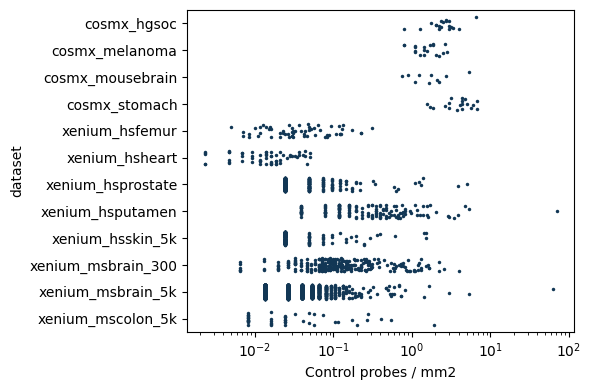

In [94]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

# Create the stripplot
plt.figure(figsize=(6, 4))
ax = sns.stripplot(data=all_control, x='control_density', y='dataset', alpha=1, jitter=0.25,s=2.5,c='#123755')
plt.xscale('log')

plt.xlabel('Control probes / mm2')
plt.tight_layout()

plt.savefig(os.path.join(saving_path, 'control_probe_density.pdf'), bbox_inches='tight')
plt.show()


In [96]:
all_control.sort_values(by='control_density')

,level_0,index,count,logfoldratio_over_noise,control_probe,p_value_Poisson,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular,moran_I,...,moran_var_norm,moran_pval_norm_fdr_bh,in_out_spearmanR,in_out_pvalue,proportion_of_colocalized,dataset,Gene,area_profiled_um2,control_density,technology
20823,20823,UnassignedCodeword_12447,0.0,-inf,True,1.0,1.000000,0.000000,inf,NaN,...,0.000017,NaN,NaN,NaN,0.000000,xenium_hsskin_5k,20823,4.093351e+07,0.000000,Xenium
20807,20807,UnassignedCodeword_4363,0.0,-inf,True,1.0,1.000000,0.000000,inf,NaN,...,0.000017,NaN,NaN,NaN,0.000000,xenium_hsskin_5k,20807,4.093351e+07,0.000000,Xenium
20805,20805,UnassignedCodeword_4071,0.0,-inf,True,1.0,1.000000,0.000000,inf,NaN,...,0.000017,NaN,NaN,NaN,0.000000,xenium_hsskin_5k,20805,4.093351e+07,0.000000,Xenium
20820,20820,UnassignedCodeword_11633,0.0,-inf,True,1.0,1.000000,0.000000,inf,NaN,...,0.000017,NaN,NaN,NaN,0.000000,xenium_hsskin_5k,20820,4.093351e+07,0.000000,Xenium
20819,20819,UnassignedCodeword_10703,0.0,-inf,True,1.0,1.000000,0.000000,inf,NaN,...,0.000017,NaN,NaN,NaN,0.000000,xenium_hsskin_5k,20819,4.093351e+07,0.000000,Xenium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24840,24840,DeprecatedCodeword_15560,4667.0,6.656512,True,0.0,0.579625,0.420375,-0.709211,0.081752,...,0.000006,NaN,NaN,NaN,0.131204,xenium_msbrain_5k,24840,7.481115e+07,62.383750,Xenium
13025,13025,NegControlProbe_00041,1798.0,3.166332,True,0.0,0.471643,0.528357,-0.780342,0.103373,...,0.000019,NaN,NaN,NaN,0.151815,xenium_hsputamen,13025,2.546095e+07,70.617959,Xenium
11147,11147,nan,NaN,NaN,True,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,xenium_hsprostate,11147,4.085399e+07,NaN,Xenium
13883,13883,nan,NaN,NaN,True,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,xenium_hsskin_5k,13883,4.093351e+07,NaN,Xenium


In [115]:
# Prostate 

sdata = sd.read_zarr( '/media/sergio/Meninges/troutpy/rois/xenium_mscolon_5k/data_processed.zarr')

In [108]:
sdata['xrna_metadata'].var.sort_values(by='in_out_spearmanR',ascending=False).head(20)

,count,logfoldratio_over_noise,control_probe,p_value_Poisson,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh,in_out_spearmanR,in_out_pvalue,proportion_of_colocalized,ks_stat,ks_pval,ad_stat,lr_stat,mean_displacement,-log_ks_pval
Myh11,23577,6.915291,False,0.0,0.962082,0.037918,-0.206856,0.328901,0.0,0.000013,NaN,0.662991,0.0,0.598779,0.401892,0.000000e+00,2514.728603,57226.956520,13.750065,690.775528
Des,11290,6.178937,False,0.0,0.966631,0.033369,-0.074344,0.296051,0.0,0.000013,NaN,0.603809,0.0,0.451746,0.401303,0.000000e+00,1232.231401,26602.229878,14.224961,690.775528
Rgs5,8416,5.885154,False,0.0,0.969400,0.030600,0.015154,0.282212,0.0,0.000013,NaN,0.602711,0.0,0.422905,0.363259,0.000000e+00,894.080103,17220.499279,12.630178,690.775528
Mylk,12871,6.309996,False,0.0,0.973256,0.026744,0.153811,0.249360,0.0,0.000013,NaN,0.594287,0.0,0.470538,0.378934,0.000000e+00,1353.082221,28290.205066,13.020890,690.775528
Myl9,7839,5.814131,False,0.0,0.976021,0.023979,0.265766,0.201843,0.0,0.000013,NaN,0.569685,0.0,0.363575,0.391783,0.000000e+00,766.559819,17226.274250,15.584866,690.775528
Tagln,9011,5.953465,False,0.0,0.976143,0.023857,0.270995,0.209977,0.0,0.000013,NaN,0.567130,0.0,0.392648,0.383981,0.000000e+00,898.643145,19983.391727,14.226208,690.775528
Cnn1,3541,5.019428,False,0.0,0.983488,0.016512,0.646468,0.123708,0.0,0.000013,NaN,0.521078,0.0,0.226726,0.374788,0.000000e+00,320.622742,6706.733837,16.892003,690.775528
Ptn,1350,4.055124,False,0.0,0.938263,0.061737,-0.719390,0.242170,0.0,0.000013,NaN,0.506802,0.0,0.289474,0.325469,8.122892e-128,133.853568,1896.824880,12.154145,292.636206
Krt19,13759,6.376712,False,0.0,0.980230,0.019770,0.463092,0.190245,0.0,0.000013,NaN,0.478601,0.0,0.456692,0.384166,0.000000e+00,1312.247485,31182.258714,17.449094,690.775528
Epcam,16752,6.573537,False,0.0,0.975331,0.024669,0.236673,0.226217,0.0,0.000013,NaN,0.465228,0.0,0.507952,0.347737,0.000000e+00,1428.434926,34246.557625,14.485066,690.775528


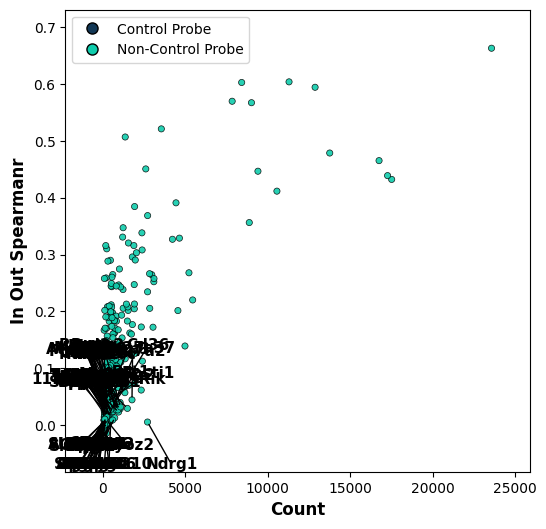

In [99]:
troutpy.pl.metric_scatter(sdata,x='count',y='in_out_spearmanR',size=20,label_bottom_n_y=100)

In [107]:
troutpy.pl.spatial_inout_expression(sdata, 'Ndrg1', spot_size_cells=7,save=True,figures_path=saving_path,custom_plot_filename='Ndrg1_scatter_in_out.png')

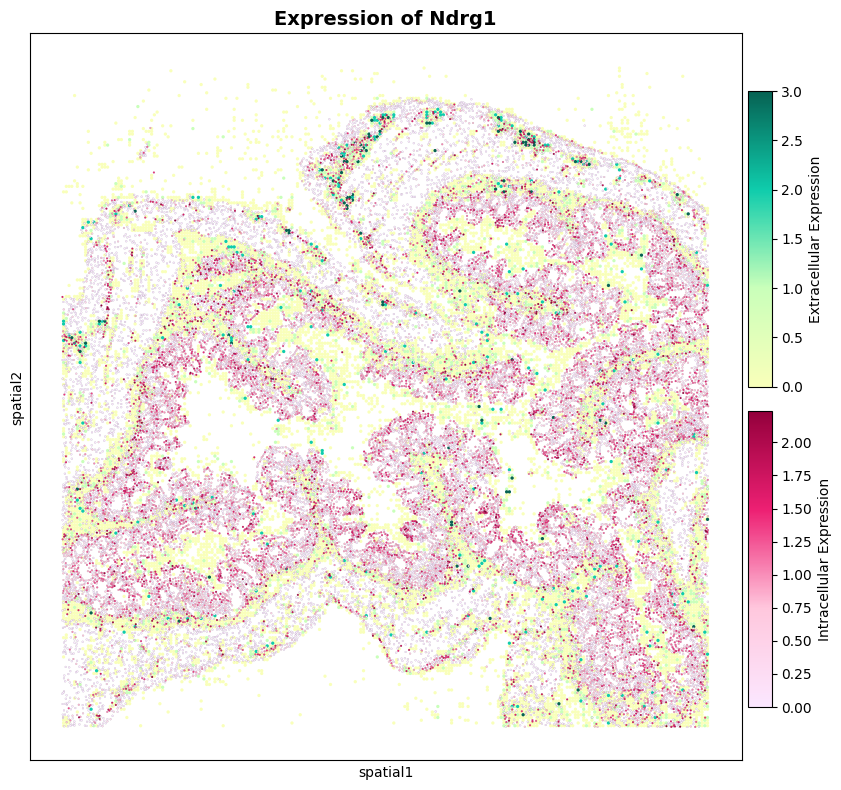

In [111]:
troutpy.pl.spatial_inout_expression(sdata, 'Ndrg1', spot_size_cells=7)

In [ ]:
troutpy.pl.

In [109]:
troutpy.pl.spatial_inout_expression(sdata, 'Myh11', spot_size_cells=7,save=True,figures_path=saving_path,custom_plot_filename='Myh11_scatter_in_out.png')

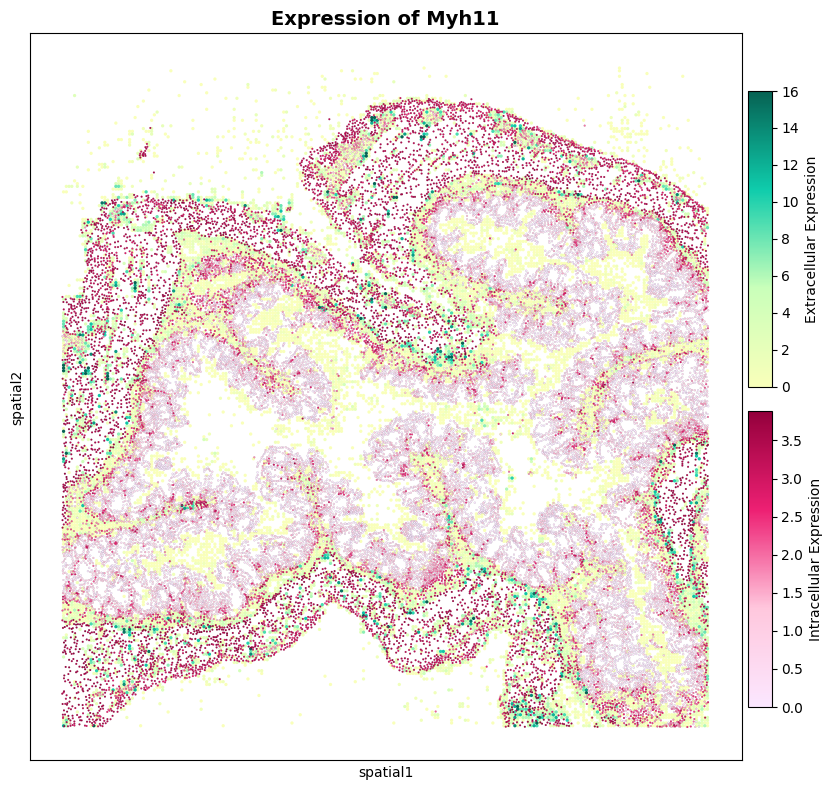

In [110]:
troutpy.pl.spatial_inout_expression(sdata, 'Myh11', spot_size_cells=7)

<Figure size 700x500 with 0 Axes>

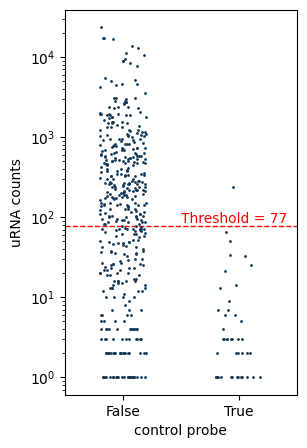

In [180]:
troutpy.pl.metric_scatter?

Signature:
troutpy.pl.metric_scatter(
    sdata: spatialdata._core.spatialdata.SpatialData,
    x: str,
    y: str,
    size: int = 1,
    non_control_probes: list[str] | None = None,
    label_top_n_x: int = 0,
    label_top_n_y: int = 0,
    label_bottom_n_x: int = 0,
    label_bottom_n_y: int = 0,
    title: str | None = None,
    linewidth: str = 0.5,
    figures_path: str = '',
    save: bool = False,
    custom_plot_filename: str = None,
    palette: str = 'troutpy',
) -> None
Docstring:
Creates a scatter plot of two specified metrics from a SpatialData object, highlighting control vs. non-control probes, with options to label top genes in each metric and save the figure.

Parameters
----------
sdata : spatialdata.SpatialData
    A SpatialData object containing 'xrna_metadata' with 'var' DataFrame.
x : str
    Metric for x-axis.
y : str
    Metric for y-axis.
non_control_probes : str
    List of specific non-control probes to include in the plot.
label_top_n_x : int
    Number of

In [198]:
# Prostate 
sdata = sd.read_zarr( '/media/sergio/Meninges/troutpy/rois/cosmx_melanoma/data_processed.zarr')

In [199]:
metadata_tab=sdata['xrna_metadata'].var

In [200]:
metadata_tab[metadata_tab['control_probe']]

,count,logfoldratio_over_noise,control_probe,p_value_Poisson,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh,in_out_spearmanR,in_out_pvalue,proportion_of_colocalized
NegPrb12,9,-0.693147,True,1.107003e-12,0.959641,0.040359,-0.270122,-0.009251,0.298747,0.000229,0.383437,0.037693,0.009466,0.285714
NegPrb5,16,-0.117783,True,0.000000e+00,0.926606,0.073394,-0.903195,0.013963,0.157048,0.000229,0.269008,0.023659,0.103452,0.142857
NegPrb22,12,-0.405465,True,0.000000e+00,0.955556,0.044444,-0.370821,0.008443,0.260522,0.000229,0.358126,0.011692,0.421042,0.090909
NegPrb7,13,-0.325422,True,0.000000e+00,0.953571,0.046429,-0.416575,0.011733,0.195112,0.000229,0.306438,0.026603,0.067100,0.083333
NegPrb21,10,-0.587787,True,2.198242e-14,0.952153,0.047847,-0.448154,0.003586,0.374246,0.000229,0.429447,0.024747,0.088523,0.250000
NegPrb9,18,0.000000,True,0.000000e+00,0.934783,0.065217,-0.776286,0.016632,0.118388,0.000229,0.216388,0.042635,0.003332,0.125000
NegPrb18,5,-1.280934,True,2.181806e-06,0.981481,0.018519,0.531418,-0.005972,0.377812,0.000229,0.431313,-0.001852,0.898561,0.000000
NegPrb8,9,-0.693147,True,1.107003e-12,0.960177,0.039823,-0.256201,0.013520,0.164185,0.000229,0.276065,0.007826,0.590214,0.000000
NegPrb23,12,-0.405465,True,0.000000e+00,0.957746,0.042254,-0.317978,0.012739,0.177281,0.000229,0.290845,-0.015268,0.293391,0.200000
NegPrb19,7,-0.944462,True,2.031349e-09,0.968037,0.031963,-0.028198,0.003277,0.381998,0.000229,0.432378,0.026542,0.067727,0.166667


In [201]:
np.percentile(metadata_tab.loc[metadata_tab['control_probe'],'count'],99)

17.82

<Figure size 700x500 with 0 Axes>

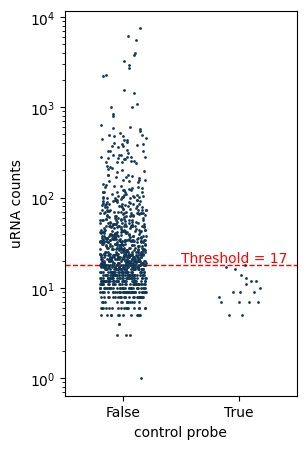

In [204]:
import matplotlib.pyplot as plt
import matplotlib

plt.figure(figsize=(7, 5))  # wider to accommodate legend
threshold=np.percentile(metadata_tab.loc[metadata_tab['control_probe'],'count'],99)
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

plt.figure(figsize=(3,5))
sns.stripplot(metadata_tab, y="count", x='control_probe',color='#123755',jitter=0.2,s=2)
plt.yscale('log')
plt.ylabel('uRNA counts')
plt.xlabel('control probe')
plt.axhline(y=threshold, color='red', linestyle='--', linewidth=1)
plt.text(x=0.5, y=threshold, s='Threshold = {}'.format(int(threshold)), color='red', va='bottom', ha='left')
plt.savefig(os.path.join(saving_path, 'uRNA_counts_melanoma_cosmx.pdf'), bbox_inches='tight')


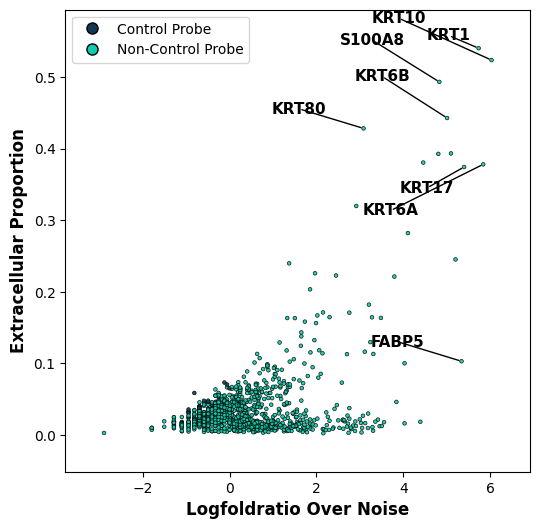

In [209]:
troutpy.pl.metric_scatter(sdata,x='logfoldratio_over_noise',y='extracellular_proportion',size=7,label_top_n_y=5,label_top_n_x=5, figures_path=saving_path,
            save=True,custom_plot_filename='extracellular_vs_logfoldratio_cosmx_melanoma.pdf')

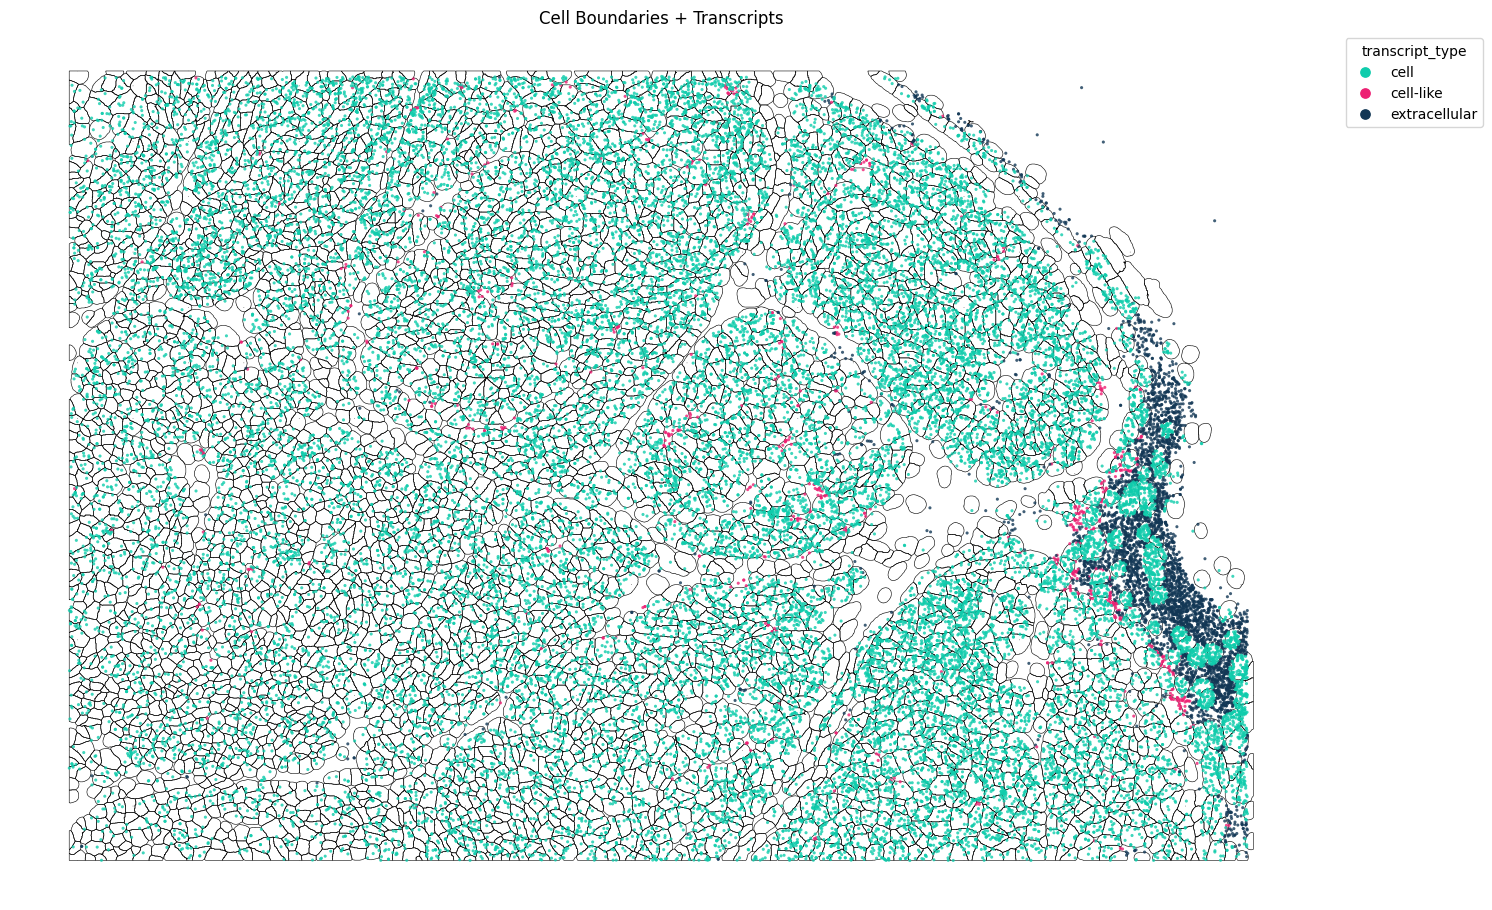

In [220]:
fig,ax=troutpy.pl.spatial_transcripts(sdata,gene_list=['FABP5'],shapes_key='shapes',boundary_linewidth=0.4,figsize=(15,15),scatter_size=5)
plt.savefig(os.path.join(saving_path,'FABP5_spatial_cosmx_melanoma.png'))